## Modeling Dataset Construction

This notebook builds and evaluates predictive models for response-time estimation.

### Objectives
- Construct a leakage-aware feature set
- Use time-based train/validation/test splits
- Benchmark CatBoost against simple baselines
- Improve generalization through feature design and tuning


In [1]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns, datetime as dt, numpy as np, glob, os
import sys
!{sys.executable} -m pip install pyarrow

pd.set_option('display.max_columns', None)

DRIVE_URL = "https://drive.google.com/uc?export=download&id=1F06NYKBF8loCTPEaPT_qIhcQy2T5iM6H"
COMBINED_DATA_PATH = "get_it_done_closed_16-25.csv"
DATA_PATH = "data.csv"

# Preferred: already-combined local CSV. Fallback: local annual CSVs, then downloaded CSV.
if os.path.exists(COMBINED_DATA_PATH):
    all_data = pd.read_csv(COMBINED_DATA_PATH, low_memory=False)
    all_data = all_data.drop(columns=[c for c in all_data.columns if c.startswith("Unnamed:")])
    print(f"Loaded combined dataset from {COMBINED_DATA_PATH}: {len(all_data):,} rows")
else:
    all_files = sorted(glob.glob("csv_files/get_it_done_requests_closed_20*_datasd.csv"))

    if all_files:
        print(f"Loading {len(all_files)} local annual CSV files from csv_files/...")
        df_list = []
        for file in all_files:
            year = file.split('_')[-2]
            df = pd.read_csv(file, low_memory=False)
            if 'year' not in df.columns:
                df['year'] = year
            df_list.append(df)
            print(f"Loaded {year}: {len(df)} rows")
        all_data = pd.concat(df_list, ignore_index=True)
    else:
        if not os.path.exists(DATA_PATH):
            print("No combined or annual CSV files found. Attempting Google Drive download...")
            try:
                import gdown
                gdown.download(DRIVE_URL, DATA_PATH, quiet=False)
            except Exception as e:
                raise RuntimeError(
                    "Could not load local CSVs and automatic download failed. "
                    "Install gdown (`pip install gdown`) or place data.csv in project root."
                ) from e

        all_data = pd.read_csv(DATA_PATH, low_memory=False)
        if 'year' not in all_data.columns and 'date_requested' in all_data.columns:
            all_data['date_requested'] = pd.to_datetime(all_data['date_requested'], errors='coerce')
            all_data['year'] = all_data['date_requested'].dt.year
        print(f"Loaded single-file dataset: {len(all_data):,} rows")

if 'year' not in all_data.columns and 'date_requested' in all_data.columns:
    all_data['date_requested'] = pd.to_datetime(all_data['date_requested'], errors='coerce')
    all_data['year'] = all_data['date_requested'].dt.year

# Data Cleaning
master = all_data[all_data["status"] != "Referred"].drop(columns=["referred"])
# Clean neighborhood names
master["comm_plan_name"] = master["comm_plan_name"].str.title()
def clean_case_type(case):
    if not isinstance(case,str):
        return case

    if "graffiti" in case.lower():
        return "Graffiti"
    return case

#Drop rows where service_name == "Other"(vague)
before_rows = len(master)
master = master[master["service_name"] != "Other"]
print(f"✓ Dropped 'Other' service type: {before_rows - len(master):,} rows")
#Remove invalid case_age_days (negative values)
before_rows = len(master)
master = master[master["case_age_days"] >= 0]
print(f"✓ Removed invalid case_age_days: {before_rows - len(master):,} rows")

#Remove duplicates (same service_request_id)
before_rows = len(master)
master = master[~master['service_request_id'].duplicated()]
print(f"✓ Removed duplicates: {before_rows - len(master):,} rows")

# keep consistent case types
master["service_name"] = master["service_name"].apply(clean_case_type)




[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: pip install --upgrade pip
Loading 10 local annual CSV files from csv_files/...
Loaded 2016: 33631 rows


/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_4067/1218280786.py:18: DtypeWarning: Columns (7,21) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Loaded 2017: 139500 rows


/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_4067/1218280786.py:18: DtypeWarning: Columns (2,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Loaded 2018: 169603 rows


/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_4067/1218280786.py:18: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Loaded 2019: 302699 rows


/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_4067/1218280786.py:18: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Loaded 2020: 280071 rows


/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_4067/1218280786.py:18: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


Loaded 2021: 359879 rows
Loaded 2022: 349241 rows
Loaded 2023: 432431 rows
Loaded 2024: 429933 rows
Loaded 2025: 378618 rows
✓ Dropped 'Other' service type: 26,693 rows
✓ Removed invalid case_age_days: 670 rows
✓ Removed duplicates: 17 rows


## Feature Engineering (Initial)

This section creates baseline temporal, text, and request-context features for first-pass modeling.


In [2]:
# Adding Features for modeling

model_data = master.copy()
#handles outliers
model_data = model_data[model_data["case_age_days"]<= 365*2]
# Continue with model_data (already filtered for outliers)
# Continue with model_data (already filtered for outliers)
print("\n=== FEATURE ENGINEERING ON MODEL_DATA ===")
print(f"Starting with {len(model_data):,} rows (after outlier removal)")

# Parse dates
model_data['date_requested'] = pd.to_datetime(model_data['date_requested'], errors='coerce')

# Temporal features
model_data['year'] = model_data['date_requested'].dt.year
model_data['month'] = model_data['date_requested'].dt.month
model_data['day_of_week'] = model_data['date_requested'].dt.dayofweek
model_data['hour'] = model_data['date_requested'].dt.hour
model_data['quarter'] = model_data['date_requested'].dt.quarter
model_data['is_weekend'] = (model_data['day_of_week'] >= 5).astype(int)

# Location features
model_data['is_district_56'] = model_data['council_district'].isin([5, 6]).astype(int)

# Fill missing council_district with 0 (Unknown)
missing_district = model_data['council_district'].isna().sum()
model_data['council_district'] = model_data['council_district'].fillna(0)
print(f"✓ Filled {missing_district:,} missing council_districts with 0 (Unknown)")

# Request type features
infrastructure_types = [
    'Pothole',
    'Street Light Maintenance',
    'Traffic Signal Issue',
    'Traffic Signal Timing',
    'Traffic Sign Maintenance',
    'Sidewalk Repair Issue',
    'Pavement Maintenance',
    'Street Repair',
    'Curb Repair'
]
model_data['is_infrastructure'] = model_data['service_name'].isin(infrastructure_types).astype(int)
model_data['is_followup'] = model_data['service_request_parent_id'].notna().astype(int)

# Text features
model_data['description_length'] = model_data['public_description'].str.len().fillna(0)
model_data['has_description'] = (model_data['description_length'] > 0).astype(int)

# Log-transformed target for regression
model_data['log_wait'] = np.log1p(model_data['case_age_days'])

# Target variable for classification
model_data['response_category'] = pd.cut(
    model_data['case_age_days'],
    bins=[0, 3, 7, 21, 90,730],
    labels=['very_fast', 'fast', 'medium', 'slow',"super_slow"],
    include_lowest=True
)

print("✓ Created all features")
# Dropping columns
columns_to_drop = [
    'date_closed',  # Already have case_age_days
    'service_request_id',  # Just an ID
    'service_request_parent_id',  # Used for is_followup feature
    'public_description',  # Used for description_length
    'sap_notification_number',  # Internal ID
    'specify_the_issue',  # Too many missing
    'public_url',  # Not useful for prediction
    'iamfloc',  # Internal code
    'floc',  # Internal code
    'park_name',  # Too many missing
]
model_data = model_data.drop(columns=columns_to_drop)

model_data['has_service_name_detail'] = model_data['service_name_detail'].notna().astype(int)
print(f"✓ Dropped {len(columns_to_drop)} unnecessary columns")

# Summary
print("\n=== MODEL DATA SUMMARY ===")
print(f"Total rows: {len(model_data):,}")
print(f"Total columns: {len(model_data.columns)}")

print(f"\nTarget variable (case_age_days) statistics:")
print(model_data['case_age_days'].describe())

print(f"\nResponse category distribution:")
print(model_data['response_category'].value_counts())

print(f"\nKey features created:")
print(f"  - Temporal: year, month, day_of_week, hour, quarter, is_weekend")
print(f"  - Location: is_district_56, council_district (0 = Unknown)")
print(f"  - Request type: is_infrastructure, is_followup")
print(f"  - Text: description_length, has_description")
print(f"  - Target: response_category (very_fast/fast/medium/slow)")

# Check for any remaining missing values in key columns
print("\n=== MISSING VALUES CHECK ===")
key_cols = ['service_name', 'council_district', 'case_age_days', 'year', 'month', 'day_of_week']
missing_summary = model_data[key_cols].isna().sum()
print(missing_summary[missing_summary > 0] if missing_summary.sum() > 0 else "No missing values in key columns ✓")

print(f"\n✓ 'model_data' ready with {len(model_data):,} rows and {len(model_data.columns)} columns")
print(f"✓ Original 'master' dataframe preserved for EDA")



=== FEATURE ENGINEERING ON MODEL_DATA ===
Starting with 2,453,645 rows (after outlier removal)
✓ Filled 32,066 missing council_districts with 0 (Unknown)
✓ Created all features
✓ Dropped 10 unnecessary columns

=== MODEL DATA SUMMARY ===
Total rows: 2,453,645
Total columns: 28

Target variable (case_age_days) statistics:
count    2.453645e+06
mean     3.295286e+01
std      8.362735e+01
min      0.000000e+00
25%      1.000000e+00
50%      5.000000e+00
75%      2.200000e+01
max      7.300000e+02
Name: case_age_days, dtype: float64

Response category distribution:
response_category
very_fast     1067828
medium         423695
slow           399743
fast           340060
super_slow     222319
Name: count, dtype: int64

Key features created:
  - Temporal: year, month, day_of_week, hour, quarter, is_weekend
  - Location: is_district_56, council_district (0 = Unknown)
  - Request type: is_infrastructure, is_followup
  - Text: description_length, has_description
  - Target: response_category (v

## Feature Engineering (Refinement Iterations)

This section adds and tests stronger features after baseline evaluation,(mainly for service_name_detail_clean) including cleaned categorical fields and interaction/context features.


In [3]:
import numpy as np
import re

model_data = model_data.copy()

def norm_text(x):
    x = str(x)
    x = x.strip().lower()
    x = re.sub(r"\s+", " ", x)   # collapse repeated spaces
    return x

# Raw strings
s_raw = model_data["service_name"].fillna("Missing").astype(str)
d_raw = model_data["service_name_detail"].fillna("Missing").astype(str)

# Normalized strings for matching only
s_norm = s_raw.map(norm_text)
d_norm = d_raw.map(norm_text)

# Same-as-service flag using normalized text
same_mask = d_norm == s_norm

# Build cleaned detail
model_data["service_name_detail_clean"] = np.where(
    same_mask,
    "SameAsService",
    d_raw
).astype(str)

# Rare bucket after same-as collapse
counts = model_data["service_name_detail_clean"].value_counts()
rare = counts[counts < 150].index
model_data["service_name_detail_clean"] = model_data["service_name_detail_clean"].replace(rare, "Other")

# Extra-detail indicator
model_data["has_extra_detail"] = (~same_mask).astype(int)

print(model_data["service_name_detail_clean"].value_counts().head(20))



service_name_detail_clean
Missing                                   851279
SameAsService                             650084
72 Hour Violation                         286225
Graffiti Removal                          118054
Parking Zone Violation                     49997
STREET LIGHT OUT                           46364
Potential Missed Collection                31723
LIGHTS OUT                                 22466
Other                                      22413
Container Left Out                         20556
CONCRETE SIDEWALK REPAIR ISSUE             20082
LIGHTS ON FLASH                            16853
SWPP - Storm Water Polution Prevention     14604
Red Zone                                   14586
Graffiti Removal - Commercial              13085
DRAIN INLET                                11635
EVALUATE TREE FOR REMOVAL                   9118
Sidewalk                                    9078
Commercial Property                         8903
Graffiti                                   

In [4]:
model_data = model_data.copy()

# 1) Prep
model_data["date_requested"] = pd.to_datetime(model_data["date_requested"], errors="coerce")
model_data = model_data.dropna(subset=["date_requested"]).sort_values("date_requested").reset_index(drop=True)

model_data["service_name"] = model_data["service_name"].fillna("Missing").astype(str)
model_data["comm_plan_name"] = model_data["comm_plan_name"].fillna("Missing").astype(str)

# helper for rolling counts
model_data["_one"] = 1.0

# 2) 30-day workload features (leakage-safe: prior window only)
# Build each rolling feature within group and return values aligned to original row index.
model_data["workload_30d_service"] = (
    model_data.groupby("service_name", group_keys=False)
    .apply(
        lambda g: pd.Series(
            g.set_index("date_requested")["_one"].rolling("30D", closed="left").sum().to_numpy(),
            index=g.index,
        )
    )
    .fillna(0)
)

model_data["workload_30d_neighborhood"] = (
    model_data.groupby("comm_plan_name", group_keys=False)
    .apply(
        lambda g: pd.Series(
            g.set_index("date_requested")["_one"].rolling("30D", closed="left").sum().to_numpy(),
            index=g.index,
        )
    )
    .fillna(0)
)

model_data["workload_30d_service_neighborhood"] = (
    model_data.groupby(["service_name", "comm_plan_name"], group_keys=False)
    .apply(
        lambda g: pd.Series(
            g.set_index("date_requested")["_one"].rolling("30D", closed="left").sum().to_numpy(),
            index=g.index,
        )
    )
    .fillna(0)
)

# 3) Interaction feature
model_data["service_x_neighborhood"] = (
    model_data["service_name"] + " | " + model_data["comm_plan_name"]
)

# optional: collapse rare interaction categories
vc = model_data["service_x_neighborhood"].value_counts()
rare = vc[vc < 100].index
model_data["service_x_neighborhood"] = model_data["service_x_neighborhood"].replace(rare, "Other")

# cleanup
model_data = model_data.drop(columns=["_one"])



/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_4067/236868000.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_4067/236868000.py:28: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_4067/236868000.py:39: FutureWarning: DataFrameGroupBy.apply operated on the grouping column

## CatBoost Modeling

CatBoost is used to handle mixed numerical/categorical tabular data with minimal manual encoding and strong baseline performance on operational datasets.


## Validation Strategy

A strict time-based split is used to mimic deployment conditions and avoid future-to-past leakage:
- Train: earlier period
- Validation: intermediate period
- Test: most recent period


## Train/Validation/Test Feature Assembly

This section defines numeric/categorical feature lists, applies consistent categorical preprocessing, and builds model matrices for each split.


In [6]:
cat_df = model_data[model_data["year"] >= 2023]
x_numerical = ['year', 'month', 'description_length', 'hour', 'is_followup','day_of_week', "workload_30d_service", "workload_30d_neighborhood", "workload_30d_service_neighborhood"]
x_cat = ['service_name', 'council_district', 'comm_plan_name', 'case_origin', 'service_name_detail_clean', 'case_record_type', "service_x_neighborhood"]
x_numerical.sort()
x_cat.sort()
y = 'log_wait'
x_total = x_numerical + x_cat
cat_df = cat_df.copy()
for c in x_cat:
    cat_df[c] = cat_df[c].fillna('Missing').astype(str)

train_df = cat_df[cat_df['date_requested'] < '2025-01-01'].copy()
valid_df = cat_df[(cat_df['date_requested'] >= '2025-01-01') & (cat_df['date_requested'] < '2025-07-01')].copy()
test_df = cat_df[cat_df['date_requested'] >= '2025-07-01'].copy()

print(f'train_df shape is {train_df.shape} | {len(train_df)/len(cat_df)*100}%')
print(f'valid_df shape is {valid_df.shape} | {len(valid_df)/len(cat_df)*100}%')
print(f'test_df shape is {test_df.shape} | {len(test_df)/len(cat_df)*100}%')

X_train = train_df[x_total]
X_valid = valid_df[x_total]
X_test = test_df[x_total]

y_train = train_df[y]
y_valid = valid_df[y]
y_test = test_df[y]

from catboost import CatBoostRegressor
cat_boost = CatBoostRegressor(
    loss_function="RMSE",
    eval_metric="RMSE",
    iterations=1000,

    learning_rate=0.05,
    depth=6,
    random_seed = 42,
    od_type = 'Iter',
    od_wait = 50,
    verbose = 100,
    
)

cat_model = cat_boost.fit(X_train, y_train, cat_features=x_cat, eval_set=(X_valid, y_valid), use_best_model=True)

results_log = cat_model.predict(X_test)



train_df shape is (764981, 34) | 70.42675067758661%
valid_df shape is (163796, 34) | 15.079616427056328%
test_df shape is (157431, 34) | 14.49363289535706%
0:	learn: 1.5501659	test: 1.4704787	best: 1.4704787 (0)	total: 183ms	remaining: 3m 2s
100:	learn: 0.9988709	test: 1.0550233	best: 1.0525353 (54)	total: 10.2s	remaining: 1m 31s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 1.052535344
bestIteration = 54

Shrink model to first 55 iterations.


## Baseline CatBoost Results

This section reports baseline CatBoost performance before extensive tuning and feature expansion.


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

evals = cat_model.get_evals_result()
print(evals.keys())
print(evals['validation']['RMSE'][-5:])

true_log = y_test.values

pred_days = np.expm1(results_log)
true_days = np.expm1(true_log)
## Day results

r2_days = r2_score(true_days, pred_days)
rmse_days = np.sqrt(mean_squared_error(true_days, pred_days))
mae_days = mean_absolute_error(true_days, pred_days)

## Log results
r2_log = r2_score(true_log, results_log)
rmse_log = np.sqrt(mean_squared_error(true_log, results_log))
mae_log = mean_absolute_error(true_log, results_log)

print(f"R^2 in Days is {np.round(r2_days, 3)}")
print(f"RSME in Days is {np.round(rmse_days, 3)}")
print(f"MAE in Days is {np.round(mae_days, 3)} days")
print()
print(f"R^2 Logged is {np.round(r2_log, 3)}")
print(f"RSME Logged is {np.round(rmse_log, 3)}")
print(f"MAE Logged is {np.round(mae_log, 3)}")
print()
residuals = pred_days - true_days
print('Mean residual:', residuals.mean())
print('% underpredicted:', (residuals < 0).mean())
print('% overpredicted:', (residuals > 0).mean())


# returns a list of important features aligned to the training feature order
# so we will put it in a dataframe with it to see the ranking
feature_importance = cat_model.get_feature_importance()

feature_ranking = pd.DataFrame({"Feature":X_train.columns, "Importance":feature_importance}).sort_values('Importance', ascending=False)
feature_ranking


dict_keys(['learn', 'validation'])
[1.0550232773641297, 1.056858553859032, 1.0564425416851584, 1.0567943188121367, 1.0568357938073674]
R^2 in Days is 0.241
RSME in Days is 17.322
MAE in Days is 8.299 days

R^2 Logged is 0.446
RSME Logged is 0.979
MAE Logged is 0.726


,Feature,Importance
9,case_origin,28.870911
14,service_name_detail_clean,28.410644
13,service_name,17.521145
10,case_record_type,13.499195
15,service_x_neighborhood,3.513271
8,year,2.078158
3,is_followup,2.060056
6,workload_30d_service,1.880694
4,month,1.237227
2,hour,0.635719


## Median Baseline

A naive median predictor is used as a reference point to verify that the model provides meaningful lift over a simple baseline.


In [ ]:

train_median = train_df['case_age_days'].median()
prediction_median = np.full(len(y_test), train_median)

median_r2_days = r2_score(true_days, prediction_median)
median_rmse_days = np.sqrt(mean_squared_error(true_days, prediction_median))
median_mae_days = mean_absolute_error(true_days, prediction_median)

print(f"R^2 in Days is {np.round(median_r2_days, 3)}")
print(f"RSME in Days is {np.round(median_rmse_days, 3)}")
print(f"MAE in Days is {np.round(median_mae_days, 3)} days")

R^2 in Days is -0.091
RSME in Days is 20.769
MAE in Days is 9.709 days


### Trying it without rolling window bias(no 2025 and everything less than a year)
- With service_name_clean R^2 Days is 0.229
RSME Days is 34.859
MAE Days is 13.341
- Without service R^2 Days is 0.216
RSME Days is 35.15
MAE Days is 13.185
- Without service and case_record_type R^2 Days is 0.134
RSME Days is 36.949
MAE Days is 13.813


In [ ]:
x_numerical = ['year', 'month', 'description_length', 'hour', 'is_followup','day_of_week', "workload_30d_service", "workload_30d_neighborhood", "workload_30d_service_neighborhood"]
x_cat = ['service_name', 'council_district', 'comm_plan_name', 'case_origin', 'service_x_neighborhood', 'case_record_type', ]# 
x_numerical.sort()
x_cat.sort()
y = 'case_age_days'
x_total = x_numerical + x_cat
year_df = cat_df.copy()
year_df = year_df[(year_df['date_requested'] < '2025-01-01') & (year_df['case_age_days'] <= 365)]
year_df = year_df.sort_values('date_requested')
for c in x_cat:
    year_df[c] = year_df[c].fillna('Missing').astype(str)
shape = len(year_df)
train_df = year_df[:int(shape*0.7)].copy()
valid_df = year_df[int(shape*.7):int(shape*.85)].copy()
test_df = year_df[int(shape*.85):].copy()

print(f'train_df shape is {train_df.shape} | {len(train_df)/len(year_df)*100}%')
print(f'valid_df shape is {valid_df.shape} | {len(valid_df)/len(year_df)*100}%')
print(f'test_df shape is {test_df.shape} | {len(test_df)/len(year_df)*100}%')




train_df shape is (527721, 34) | 69.99992041258119%
valid_df shape is (113083, 34) | 14.999973470860391%
test_df shape is (113084, 34) | 15.00010611655843%


In [ ]:
X_train = train_df[x_total]
X_valid = valid_df[x_total]
X_test = test_df[x_total]

y_train = train_df[y]
y_valid = valid_df[y]
y_test = test_df[y]
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
cat_boost = CatBoostRegressor(
    loss_function="Huber:delta=30.0",
    eval_metric="MAE",
    iterations=1000,

    learning_rate=0.05,
    depth=6,
    random_seed = 42,
    od_type = 'Iter',
    od_wait = 50,
    verbose = 100,

)

cat_model = cat_boost.fit(X_train, y_train, cat_features=x_cat, eval_set=(X_valid, y_valid), use_best_model=True)

results_days = cat_model.predict(X_test)


evals = cat_model.get_evals_result()
print(evals.keys())
print(evals['validation']['MAE'][-5:])

true_days = y_test.values

## Day results

r2_days = r2_score(true_days, results_days)
rmse_days = np.sqrt(mean_squared_error(true_days, results_days))
mae_days = mean_absolute_error(true_days, results_days)

print(f"R^2 Days is {np.round(r2_days, 3)}")
print(f"RSME Days is {np.round(rmse_days, 3)}")
print(f"MAE Days is {np.round(mae_days, 3)}")
print()
residuals = results_days - true_days
print('Mean residual:', residuals.mean())
print('% underpredicted:', (residuals < 0).mean())
print('% overpredicted:', (residuals > 0).mean())


# returns a list of important features aligned to the training feature order
# so we will put it in a dataframe with it to see the ranking
feature_importance = cat_model.get_feature_importance()

feature_ranking = pd.DataFrame({"Feature":X_train.columns, "Importance":feature_importance}).sort_values('Importance', ascending=False)
feature_ranking


0:	learn: 19.4409793	test: 19.5729264	best: 19.5729264 (0)	total: 69ms	remaining: 1m 8s
100:	learn: 15.0022183	test: 15.5270067	best: 15.5270067 (100)	total: 7.64s	remaining: 1m 8s
200:	learn: 14.7366108	test: 15.4325754	best: 15.4325504 (199)	total: 15.4s	remaining: 1m 1s
300:	learn: 14.5758020	test: 15.3823019	best: 15.3823019 (300)	total: 23.4s	remaining: 54.2s
400:	learn: 14.4618322	test: 15.3583369	best: 15.3576832 (396)	total: 31.6s	remaining: 47.2s
500:	learn: 14.3781659	test: 15.3346560	best: 15.3346560 (500)	total: 39.5s	remaining: 39.3s
600:	learn: 14.3110137	test: 15.3143671	best: 15.3143671 (600)	total: 47.4s	remaining: 31.4s
700:	learn: 14.2495388	test: 15.2994751	best: 15.2986555 (692)	total: 55.4s	remaining: 23.6s
800:	learn: 14.2032993	test: 15.2949207	best: 15.2932097 (783)	total: 1m 3s	remaining: 15.7s
900:	learn: 14.1632034	test: 15.2824363	best: 15.2824363 (900)	total: 1m 11s	remaining: 7.82s
999:	learn: 14.1254819	test: 15.2773870	best: 15.2768529 (988)	total: 1m 1

,Feature,Importance
13,service_name,28.262548
10,case_record_type,22.882637
6,workload_30d_service,15.127969
4,month,7.973844
8,year,7.430356
12,council_district,3.446584
3,is_followup,3.352505
9,case_origin,2.526142
14,service_x_neighborhood,2.093804
5,workload_30d_neighborhood,1.819684


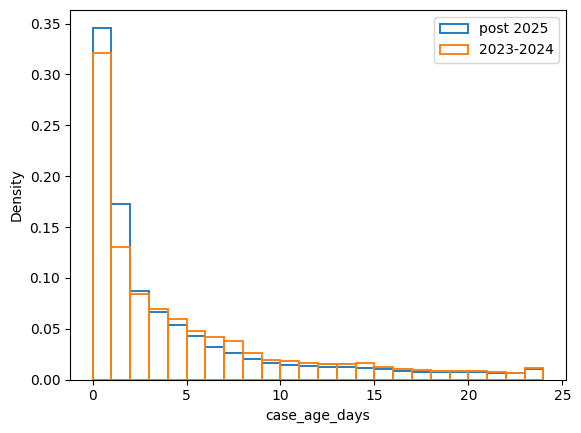

In [ ]:
analysis_2025 = cat_df[cat_df['date_requested'] > '2025-01-01']
analysis_2023_2024 = year_df.copy()
sns.histplot(cat_df[cat_df['date_requested'] > '2025-01-01']['case_age_days'], bins = np.arange(0, 25), stat='density', label = 'post 2025', fill = False)
sns.histplot(year_df['case_age_days'], bins = np.arange(0, 25), stat='density', label = '2023-2024', fill = False)
plt.legend()

In [ ]:
analysis_2025['case_age_days'].describe()


count    321227.000000
mean         13.194486
std          30.646264
min           0.000000
25%           0.000000
50%           2.000000
75%          10.000000
max         361.000000
Name: case_age_days, dtype: float64

In [ ]:
analysis_2023_2024['case_age_days'].describe()

count    753888.000000
mean         19.278735
std          46.920036
min           0.000000
25%           0.000000
50%           3.000000
75%          13.000000
max         365.000000
Name: case_age_days, dtype: float64

In [ ]:
train_median_2023_2024 = y_train.median()
prediction_median_2023_2024 = np.full(len(y_test), train_median_2023_2024)

median_r2_days = r2_score(true_days, prediction_median_2023_2024)
median_rmse_days = np.sqrt(mean_squared_error(true_days, prediction_median_2023_2024))
median_mae_days = mean_absolute_error(true_days, prediction_median_2023_2024)

print(f"R^2 in Days is {np.round(median_r2_days, 3)}")
print(f"RSME in Days is {np.round(median_rmse_days, 3)}")
print(f"MAE in Days is {np.round(median_mae_days, 3)} days")


R^2 in Days is -0.09
RSME in Days is 41.445
MAE in Days is 15.415 days


## Results Synthesis: Rolling-Window Bias Comparison

### Side-by-Side Metrics (Days)

| Model Variant | MAE | RMSE | R² |
|---|---:|---:|---:|
| CatBoost (Original Split) | **8.416** | **17.625** | **0.214** |
| CatBoost (No-2025 / <=365 / Chronological 70-15-15) | **13.341** | **34.859** | **0.229** |
| Median Baseline (Original Split) | **9.709** | **20.769** | **-0.091** |
| Median Baseline (No-2025 / <=365 / Chronological 70-15-15) | **15.415** | **41.445** | **-0.090** |

### Rolling-Window Bias Interpretation

- After switching to the no-2025, <=365 chronological split, absolute error increased for **both** CatBoost and median baseline.
- This indicates the performance shift is largely a **data-window/distribution effect**, not only model degradation.
- In the no-2025 setup, CatBoost still outperforms median baseline:
  - MAE improvement: **15.415 -> 13.341** (about **2.07 days**)
  - RMSE improvement: **41.445 -> 34.859**




In [ ]:
year_df.columns

Index(['date_requested', 'case_age_days', 'case_record_type', 'service_name',
       'service_name_detail', 'status', 'lat', 'lng', 'street_address',
       'zipcode', 'council_district', 'comm_plan_code', 'comm_plan_name',
       'case_origin', 'year', 'month', 'day_of_week', 'hour', 'quarter',
       'is_weekend', 'is_district_56', 'is_infrastructure', 'is_followup',
       'description_length', 'has_description', 'log_wait',
       'response_category', 'has_service_name_detail',
       'service_name_detail_clean', 'has_extra_detail', 'workload_30d_service',
       'workload_30d_neighborhood', 'workload_30d_service_neighborhood',
       'service_x_neighborhood'],
      dtype='object')

### Testing out with logging the time first and exponentiating afterwards
- For this window size, logging seems to help versus not logging as you can see with the results compared to the base case above
- Removing service_name_detail_clean seemed to drop mae from 13.2 to 13.1, perhaps it was causing overfitting or was a linear combination of other ones and the other features didn't get to be used

- Hubert with d=20& 30 R^2 in Days is 0.203
RSME in Days is 35.448
MAE in Days is 13.019 days
### Made a mistake with the hubert, forgot it was logged so it was behaving exactly like RMSE
- hubert d = 1.5, R^2 in Days is 0.209
RSME in Days is 35.299
MAE in Days is 13.005 days Mean residual: -6.259992674445461
% underpredicted: 0.466095999434049
% overpredicted: 0.533904000565951




In [ ]:
x_numerical = ['year', 'month', 'description_length', 'hour', 'is_followup','day_of_week', "workload_30d_service", "workload_30d_neighborhood", "workload_30d_service_neighborhood"]
x_cat = ['service_name', 'council_district', 'comm_plan_name', 'case_origin', 'case_record_type', 'service_x_neighborhood']
x_numerical.sort()
x_cat.sort()
y = 'log_wait'
x_total = x_numerical + x_cat
year_df = cat_df.copy()
year_df = year_df[(year_df['date_requested'] < '2025-01-01') & (year_df['case_age_days'] <= 365)]
year_df = year_df.sort_values('date_requested')
for c in x_cat:
    year_df[c] = year_df[c].fillna('Missing').astype(str)
shape = len(year_df)
train_df = year_df[:int(shape*0.7)].copy()
valid_df = year_df[int(shape*.7):int(shape*.85)].copy()
test_df = year_df[int(shape*.85):].copy()

print(f'train_df shape is {train_df.shape} | {len(train_df)/len(year_df)*100}%')
print(f'valid_df shape is {valid_df.shape} | {len(valid_df)/len(year_df)*100}%')
print(f'test_df shape is {test_df.shape} | {len(test_df)/len(year_df)*100}%')


X_train = train_df[x_total]
X_valid = valid_df[x_total]
X_test = test_df[x_total]

y_train = train_df[y]
y_valid = valid_df[y]
y_test = test_df[y]
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
cat_boost = CatBoostRegressor(
    loss_function="Huber:delta=1.5",
    eval_metric="MAE",
    iterations=1000,

    learning_rate=0.05,
    depth=6,
    random_seed = 42,
    od_type = 'Iter',
    od_wait = 50,
    verbose = 100,

)

cat_model = cat_boost.fit(X_train, y_train, cat_features=x_cat, eval_set=(X_valid, y_valid), use_best_model=True)

results_log = cat_model.predict(X_test)


evals = cat_model.get_evals_result()
print(evals.keys())
print(evals['validation']['MAE'][-5:])

true_log = y_test.values

##log results

pred_days = np.expm1(results_log)
true_days = np.expm1(true_log)
## Day results

r2_days = r2_score(true_days, pred_days)
rmse_days = np.sqrt(mean_squared_error(true_days, pred_days))
mae_days = mean_absolute_error(true_days, pred_days)

##log results
r2_log = r2_score(true_log, results_log)
rmse_log = np.sqrt(mean_squared_error(true_log, results_log))
mae_log = mean_absolute_error(true_log, results_log)

print(f"R^2 in Days is {np.round(r2_days, 3)}")
print(f"RSME in Days is {np.round(rmse_days, 3)}")
print(f"MAE in Days is {np.round(mae_days, 3)} days")
print()
print(f"R^2 Logged is {np.round(r2_log, 3)}")
print(f"RSME Logged is {np.round(rmse_log, 3)}")
print(f"MAE Logged is {np.round(mae_log, 3)}")
print()
residuals = pred_days - true_days
print('Mean residual:', residuals.mean())
print('% underpredicted:', (residuals < 0).mean())
print('% overpredicted:', (residuals > 0).mean())

# returns a list of important features aligned to the training feature order
# so we will put it in a dataframe with it to see the ranking
feature_importance = cat_model.get_feature_importance()

feature_ranking = pd.DataFrame({"Feature":X_train.columns, "Importance":feature_importance}).sort_values('Importance', ascending=False)
feature_ranking


train_df shape is (527721, 34) | 69.99992041258119%
valid_df shape is (113083, 34) | 14.999973470860391%
test_df shape is (113084, 34) | 15.00010611655843%
0:	learn: 1.3839349	test: 1.4081726	best: 1.4081726 (0)	total: 113ms	remaining: 1m 52s
100:	learn: 0.8341240	test: 0.8185168	best: 0.8185168 (100)	total: 9.51s	remaining: 1m 24s
200:	learn: 0.8237163	test: 0.8088159	best: 0.8088159 (200)	total: 18.2s	remaining: 1m 12s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.8060676535
bestIteration = 238

Shrink model to first 239 iterations.
dict_keys(['learn', 'validation'])
[0.8077494718419311, 0.8077002606982117, 0.8077251219373981, 0.8075107754023796, 0.8073247992499117]
R^2 in Days is 0.126
RSME in Days is 37.121
MAE in Days is 16.369 days

R^2 Logged is 0.243
RSME Logged is 1.272
MAE Logged is 0.897


,Feature,Importance
13,service_name,32.263001
9,case_origin,27.648726
10,case_record_type,23.190726
6,workload_30d_service,3.201653
1,description_length,2.653911
3,is_followup,2.540845
8,year,2.386281
4,month,2.210587
12,council_district,1.584271
5,workload_30d_neighborhood,1.034863
